# ДЗ. Распознавание рукописных цифр MNIST

Старинская Светлана, 3ФИИТ

## Задание

Построить и обучить CNN на PyTorch, измерить accuracy и показать предсказания отдельных цифр.

## 1. Импорт библиотек и константы

Фиксируем seed и используем CPU.

In [1]:
from pathlib import Path
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset, Subset
from torchvision import datasets, transforms
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
DATA = Path('../.lab-data')
DATA.mkdir(exist_ok=True)
DEVICE = torch.device('cpu')
print('Устройство:', DEVICE, '| PyTorch:', torch.__version__)

Устройство: cpu | PyTorch: 2.8.0


## 2. Данные MNIST

Из train выделяем 5 000 объектов для валидации. Тестовые 10 000 цифр используем один раз после обучения.

In [2]:
transform=transforms.ToTensor()
raw=datasets.MNIST(DATA,train=True,download=True,transform=transform)
test_data=datasets.MNIST(DATA,train=False,download=True,transform=transform)
ids=np.random.default_rng(SEED).permutation(len(raw))
train_data=Subset(raw,ids[:55000]);val_data=Subset(raw,ids[55000:])
print('Train:',len(train_data),'val:',len(val_data),'test:',len(test_data))

Train: 55000 val: 5000 test: 10000


## 3. Свёрточная сеть

Два блока Conv–ReLU–Pool: 28 → 24 → 12 → 8 → 4. Перед первым Linear получается 16×4×4=256 признаков.

In [3]:
class DigitCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features=nn.Sequential(nn.Conv2d(1,6,5),nn.ReLU(),nn.MaxPool2d(2),nn.Conv2d(6,16,5),nn.ReLU(),nn.MaxPool2d(2))
        self.classifier=nn.Sequential(nn.Flatten(),nn.Linear(256,120),nn.ReLU(),nn.Linear(120,84),nn.ReLU(),nn.Linear(84,10))
    def forward(self,x):return self.classifier(self.features(x))
model=DigitCNN()
print(model)
assert model(torch.zeros(2,1,28,28)).shape==(2,10)

DigitCNN(
  (features): Sequential(
    (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=256, out_features=120, bias=True)
    (2): ReLU()
    (3): Linear(in_features=120, out_features=84, bias=True)
    (4): ReLU()
    (5): Linear(in_features=84, out_features=10, bias=True)
  )
)


## 4. Обучение и тестирование

CrossEntropyLoss принимает logits. Во время оценки отключаем вычисление градиентов.

Эпоха 1: loss=0.4362, train=86.51%, val=95.94%, время=11.2 с
Эпоха 2: loss=0.1166, train=96.35%, val=97.16%, время=22.3 с
Эпоха 3: loss=0.0821, train=97.40%, val=97.82%, время=33.4 с
Тестовая accuracy: 98.09%


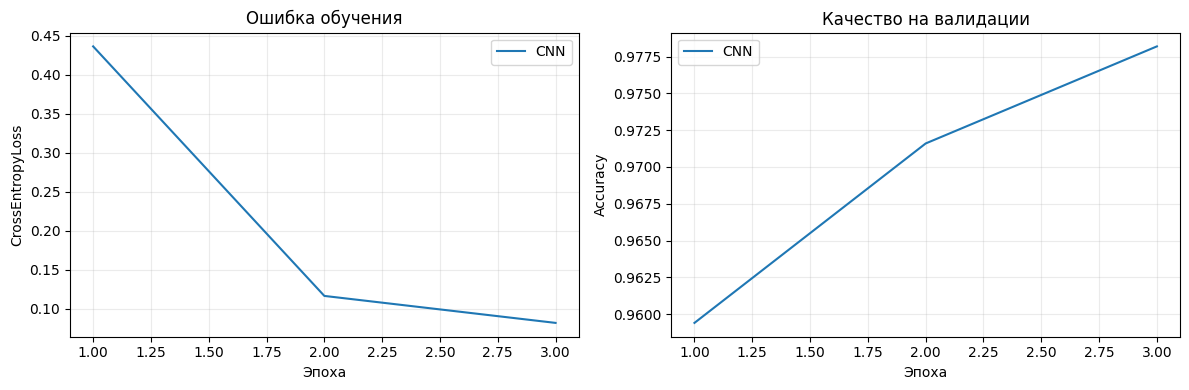

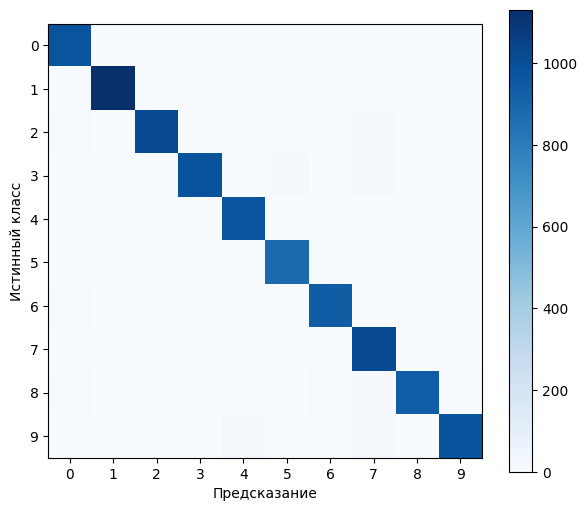

In [4]:
def fit(model, train_data, val_data, epochs=3, lr=0.001):
    torch.manual_seed(SEED)
    loader = DataLoader(train_data, batch_size=128, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED))
    val_loader = DataLoader(val_data, batch_size=256)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    history = []
    start = time.perf_counter()
    for epoch in range(epochs):
        model.train()
        loss_sum = correct = total = 0
        for x, y in loader:
            optimizer.zero_grad()
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(y)
            correct += (logits.argmax(1) == y).sum().item()
            total += len(y)
        model.eval()
        vc = vn = 0
        with torch.inference_mode():
            for x, y in val_loader:
                vc += (model(x).argmax(1) == y).sum().item()
                vn += len(y)
        row = (loss_sum / total, correct / total, vc / vn, time.perf_counter()-start)
        history.append(row)
        print(f'Эпоха {epoch+1}: loss={row[0]:.4f}, train={row[1]:.2%}, val={row[2]:.2%}, время={row[3]:.1f} с')
    return np.array(history)

def plot_histories(histories):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for name, h in histories.items():
        axes[0].plot(np.arange(1,len(h)+1),h[:,0],label=name)
        axes[1].plot(np.arange(1,len(h)+1),h[:,2],label=name)
    axes[0].set(title='Ошибка обучения',xlabel='Эпоха',ylabel='CrossEntropyLoss')
    axes[1].set(title='Качество на валидации',xlabel='Эпоха',ylabel='Accuracy')
    for ax in axes:ax.legend();ax.grid(alpha=.25)
    plt.tight_layout();plt.show()

history=fit(model,train_data,val_data,epochs=3)
plot_histories({'CNN':history})
truth=[];predictions=[]
model.eval()
with torch.inference_mode():
    for x,y in DataLoader(test_data,batch_size=256):
        truth.extend(y.tolist());predictions.extend(model(x).argmax(1).tolist())
truth=np.array(truth);predictions=np.array(predictions)
print(f'Тестовая accuracy: {(truth==predictions).mean():.2%}')
confusion=np.zeros((10,10),dtype=int)
np.add.at(confusion,(truth,predictions),1)
plt.figure(figsize=(7,6));plt.imshow(confusion,cmap='Blues');plt.xticks(range(10));plt.yticks(range(10));plt.xlabel('Предсказание');plt.ylabel('Истинный класс');plt.colorbar();plt.show()

## 5. Предсказания отдельных цифр

Показываем первые примеры и ошибки модели.

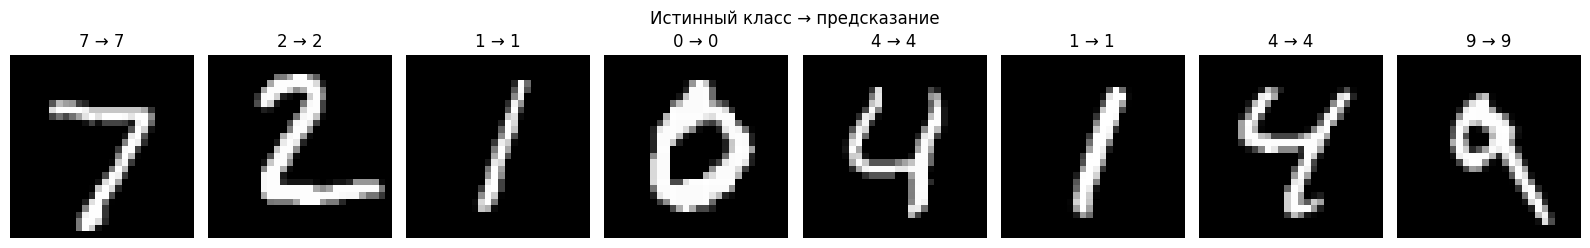

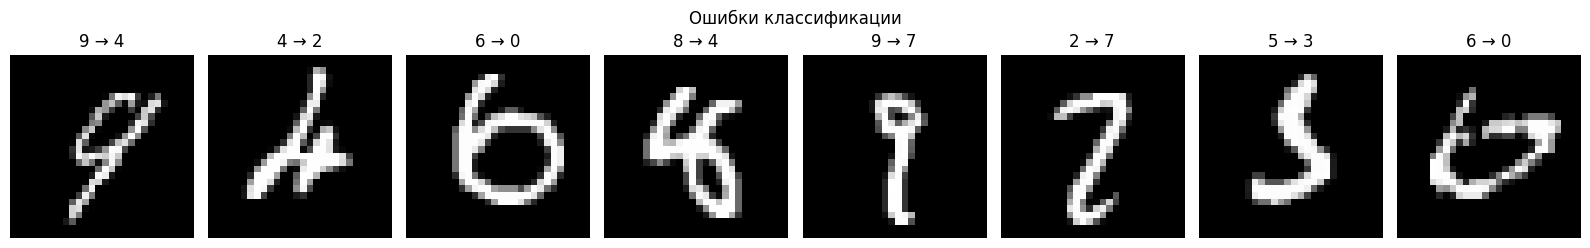

In [5]:
def show_digits(indices,title):
    fig,axes=plt.subplots(1,len(indices),figsize=(2*len(indices),2.5),squeeze=False)
    for ax,index in zip(axes.ravel(),indices):
        ax.imshow(test_data[int(index)][0].squeeze(),cmap='gray')
        ax.set_title(f'{truth[index]} → {predictions[index]}');ax.axis('off')
    fig.suptitle(title);plt.tight_layout();plt.show()
show_digits(np.arange(8),'Истинный класс → предсказание')
errors=np.flatnonzero(truth!=predictions)
if len(errors):show_digits(errors[:8],'Ошибки классификации')

## Вывод

CNN из двух свёрточных и трёх полносвязных слоёв за три эпохи получила **97,82% accuracy на validation** и **98,09% на независимом test**. CrossEntropyLoss уменьшилась с 0,4362 до 0,0821. Свёртки извлекают локальные признаки цифр, а pooling уменьшает размер карт. Матрица ошибок и примеры показывают, что отдельные неоднозначно написанные цифры модель продолжает путать. Тест не использовался для выбора параметров.